## Thinking about Math of Naive RNN

We define a naive RNN as

$$
h_t = \tanh(W_{h~\text{in}} h_{t-1} + W_x x_t + b_h) ~~~~~~~~~~~~~~ \hat{y} = W_{h~\text{out}} h_t
$$


Under this definition of our network and under a general loss funciton $\mathcal{L}$, our model will backprogate RNN weights in this manner. 


$$
\frac{\partial L}{\partial W_{h~\text{out}}} = \frac{\partial L}{\partial \hat{y}} \frac{\partial \hat{y}}{\partial W_{h~\text{out}}} ~~~~~~~~~~~~~~~ \frac{\partial L}{\partial W_x} = \frac{\partial L}{\hat{y}} \frac{\hat{y}}{h_t} \frac{h_t}{\partial W_x} ~~~~~~~~~~~~~~~ \frac{\partial L}{\partial W_{h~\text{in}}} = \frac{\partial L}{\partial \hat{y}} \frac{\partial \hat{y}}{\partial h_t} \frac{\partial h_t}{\partial W_{h~\text{in}}}
$$

## Thinking about Math of Naive RNN

We define a naive RNN as

$$
h_t = \tanh(W_{hh} h_{t-1} + W_x x_t + b_h) \qquad \hat{y}_t = W_{\text{out}} h_t
$$

with total loss $\mathcal{L} = \sum_t \mathcal{L}_t(\hat{y}_t, y_t)$.

**Readout.** $W_{\text{out}}$ only affects the current output:

$$
\frac{\partial \mathcal{L}}{\partial W_{\text{out}}} = \sum_t \frac{\partial \mathcal{L}_t}{\partial \hat{y}_t}\, h_t^\top
$$

**Recurrent and input weights.** $h_t$ depends on $W_{hh}, W_x$ at *every* earlier step, so we sum over all paths back in time (BPTT):

$$
\frac{\partial \mathcal{L}}{\partial W} = \sum_t \sum_{k \le t}
\frac{\partial \mathcal{L}_t}{\partial h_t}
\left( \prod_{j=k+1}^{t} \frac{\partial h_j}{\partial h_{j-1}} \right)
\frac{\partial^+ h_k}{\partial W}, \qquad W \in \{W_{hh}, W_x\}
$$

where $\partial^+$ is the immediate (one-step) derivative, and

$$
\frac{\partial h_j}{\partial h_{j-1}} = \mathrm{diag}(1 - h_j^2)\, W_{hh}
$$

$$
\frac{\partial^+ h_k}{\partial W_{hh}} \to \mathrm{diag}(1-h_k^2)\,(\cdot)\, h_{k-1}^\top \qquad
\frac{\partial^+ h_k}{\partial W_x} \to \mathrm{diag}(1-h_k^2)\,(\cdot)\, x_k^\top
$$

**State-based loss.** If $\mathcal{L}$ is computed on $h_t$ directly (contrastive, predictive), then
$\partial \mathcal{L} / \partial W_{\text{out}} = 0$ and the sum starts from $\partial \mathcal{L}_t / \partial h_t$.

In [1]:
import time
import jax, jax.numpy as jnp
import numpy as np
import optax

d = np.load("particles.npz")
p0  = np.stack([d["x_0"], d["y_0"]], -1).astype(np.float32)     # (N, 2)
pos = np.stack([d["x_t"], d["y_t"]], -1).astype(np.float32)     # (N, T, 2)
vel = np.stack([d["v_xt"], d["v_yt"]], -1).astype(np.float32)   # (N, T, 2)
N, T, _ = pos.shape

idx = np.random.default_rng(0).permutation(N)
n_val = N // 10
tr, va = idx[n_val:], idx[:n_val]

pos_mu = pos[tr].reshape(-1, 2).mean(0)
pos_sd = pos[tr].reshape(-1, 2).std(0) + 1e-8
vel_sd = vel[tr].reshape(-1, 2).std(0) + 1e-8

def prep(i):
    start = np.zeros((len(i), T, 2), np.float32)
    start[:, 0] = (p0[i] - pos_mu) / pos_sd                 # start position only at t=0
    u = np.concatenate([vel[i] / vel_sd, start], -1)        # (n, T, 4)
    y = (pos[i] - pos_mu) / pos_sd
    return jnp.asarray(u), jnp.asarray(y)

u_tr, y_tr = prep(tr)
u_va, y_va = prep(va)
print(u_tr.shape, y_tr.shape)

(9000, 150, 4) (9000, 150, 2)


In [2]:
def init_params(key, n_in=4, H=128, n_out=2, g=0.9):
    k1, k2, k3 = jax.random.split(key, 3)
    return {
        "W_x":   jax.random.normal(k1, (H, n_in)) / jnp.sqrt(n_in),
        "W_hh":  g * jax.nn.initializers.orthogonal()(k2, (H, H)),
        "b_h":   jnp.zeros(H),
        "W_out": jax.random.normal(k3, (n_out, H)) / jnp.sqrt(H),
        "b_out": jnp.zeros(n_out),
    }

def rnn_forward(params, u):                      # u: (T, n_in)
    def step(h, u_t):
        h = jnp.tanh(params["W_hh"] @ h + params["W_x"] @ u_t + params["b_h"])
        return h, h
    _, hs = jax.lax.scan(step, jnp.zeros(params["W_hh"].shape[0]), u)
    return hs, hs @ params["W_out"].T + params["b_out"]

batched_forward = jax.vmap(rnn_forward, in_axes=(None, 0))

def loss_fn(params, u, y):
    _, y_hat = batched_forward(params, u)
    return jnp.mean((y_hat - y) ** 2)

In [3]:
freeze = set()   # e.g. {"W_hh"} for the precoded-VPNI arm

key = jax.random.PRNGKey(0)
key, k = jax.random.split(key)
params = init_params(k)
W_hh_init = params["W_hh"]

labels = {name: ("frozen" if name in freeze else "train") for name in params}
opt = optax.multi_transform(
    {"train": optax.chain(optax.clip_by_global_norm(1.0), optax.adam(1e-3)),
     "frozen": optax.set_to_zero()},
    labels,
)
opt_state = opt.init(params)

@jax.jit
def train_step(params, opt_state, u, y):
    loss, grads = jax.value_and_grad(loss_fn)(params, u, y)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

eval_loss = jax.jit(loss_fn)

In [4]:
steps, batch = 3000, 128
history = []
t0 = time.time()
for step in range(1, steps + 1):
    key, k = jax.random.split(key)
    b = jax.random.randint(k, (batch,), 0, u_tr.shape[0])
    params, opt_state, loss = train_step(params, opt_state, u_tr[b], y_tr[b])

    if step % 250 == 0 or step == 1:
        val = float(eval_loss(params, u_va, y_va))
        drift = float(jnp.linalg.norm(params["W_hh"] - W_hh_init))
        history.append((step, float(loss), val, drift))
        print(f"step {step:5d} | train {float(loss):.4f} | val {val:.4f} | "
              f"||dW_hh|| {drift:.3f} | {time.time()-t0:.0f}s")

step     1 | train 1.1474 | val 1.0465 | ||dW_hh|| 0.128 | 1s
step   250 | train 0.1141 | val 0.0928 | ||dW_hh|| 2.005 | 8s
step   500 | train 0.0378 | val 0.0354 | ||dW_hh|| 2.224 | 15s
step   750 | train 0.0315 | val 0.0449 | ||dW_hh|| 2.375 | 23s
step  1000 | train 0.0271 | val 0.0247 | ||dW_hh|| 2.517 | 30s
step  1250 | train 0.0213 | val 0.0213 | ||dW_hh|| 2.657 | 38s
step  1500 | train 0.0262 | val 0.0222 | ||dW_hh|| 2.779 | 45s
step  1750 | train 0.0291 | val 0.0300 | ||dW_hh|| 2.903 | 52s
step  2000 | train 0.0229 | val 0.0283 | ||dW_hh|| 3.003 | 60s
step  2250 | train 0.0198 | val 0.0187 | ||dW_hh|| 3.112 | 67s
step  2500 | train 0.0142 | val 0.0152 | ||dW_hh|| 3.232 | 74s
step  2750 | train 0.0149 | val 0.0175 | ||dW_hh|| 3.333 | 82s
step  3000 | train 0.0293 | val 0.0190 | ||dW_hh|| 3.433 | 89s


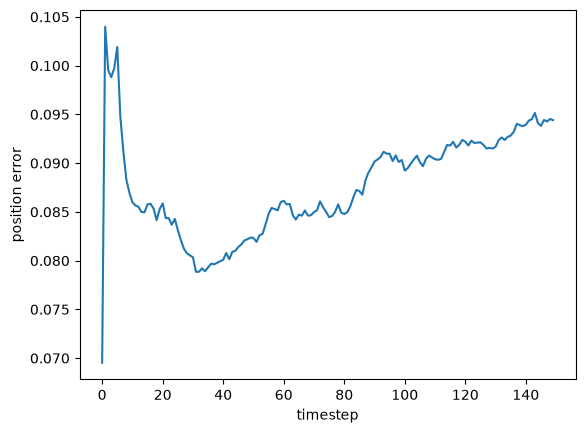

In [5]:
hs_va, y_hat = batched_forward(params, u_va)
err = np.asarray(jnp.linalg.norm((y_hat - y_va) * pos_sd, axis=-1)).mean(0)   # (T,)

import matplotlib.pyplot as plt
plt.plot(err); plt.xlabel("timestep"); plt.ylabel("position error"); plt.show()

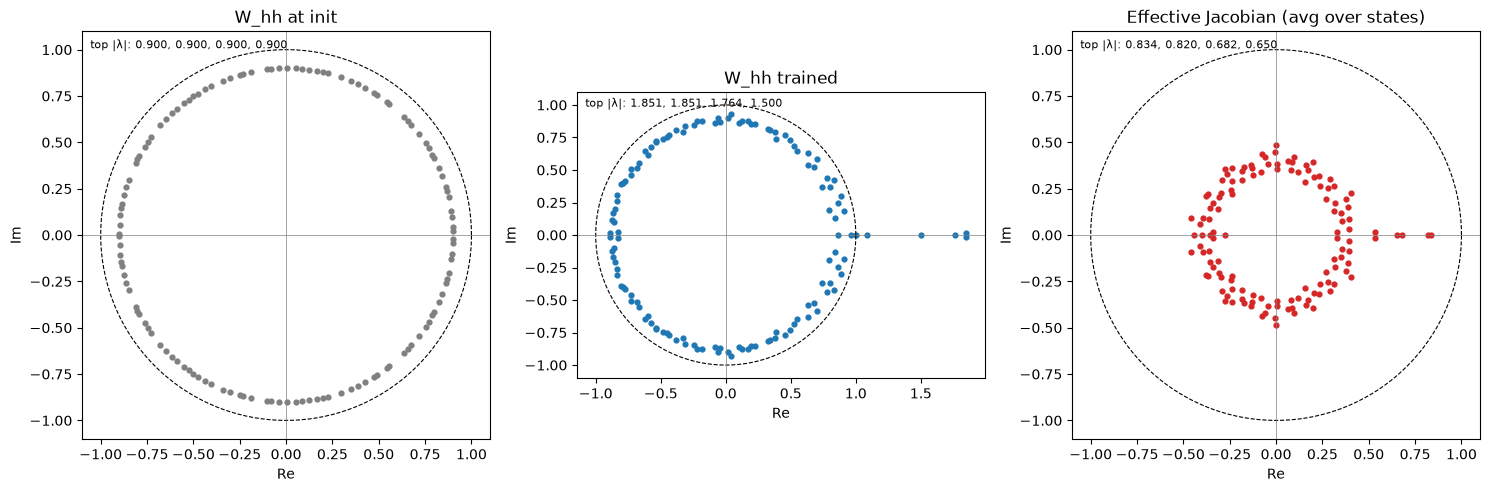

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_eigs(ax, M, title, **kw):
    ev = np.linalg.eigvals(np.asarray(M))
    th = np.linspace(0, 2*np.pi, 300)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)          # unit circle
    ax.scatter(ev.real, ev.imag, s=12, **kw)
    ax.axhline(0, c="gray", lw=0.5); ax.axvline(0, c="gray", lw=0.5)
    ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    top = np.sort(np.abs(ev))[::-1][:4]
    ax.text(0.02, 0.98, "top |λ|: " + ", ".join(f"{v:.3f}" for v in top),
            transform=ax.transAxes, va="top", fontsize=8)
    return ev

# Effective Jacobian averaged over visited states: J = diag(1 - h^2) W_hh
hs_va, _ = batched_forward(params, u_va)
h = np.asarray(hs_va).reshape(-1, hs_va.shape[-1])          # (n_val*T, H)
gain = (1 - h**2).mean(0)                                     # (H,)
J = gain[:, None] * np.asarray(params["W_hh"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_eigs(axes[0], W_hh_init, "W_hh at init", c="gray")
plot_eigs(axes[1], params["W_hh"], "W_hh trained", c="C0")
plot_eigs(axes[2], J, "Effective Jacobian (avg over states)", c="C3")
plt.tight_layout(); plt.show()

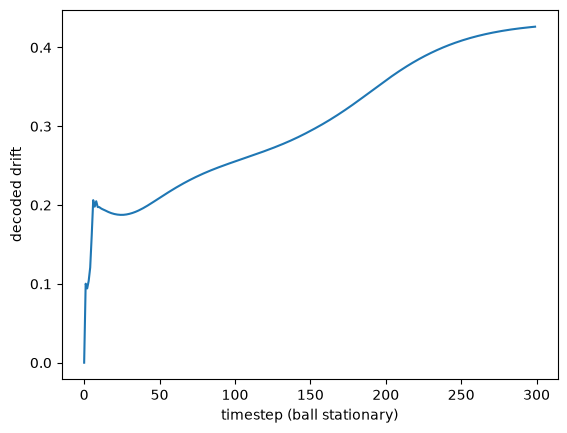

In [7]:
# Feed the true start, then zero velocity for 300 steps; does decoded position drift?
T_hold = 300
u_hold = np.zeros((u_va.shape[0], T_hold, 4), np.float32)
u_hold[:, 0, 2:] = np.asarray(u_va[:, 0, 2:])               # start position at t=0
_, y_hold = batched_forward(params, jnp.asarray(u_hold))
drift = np.linalg.norm((np.asarray(y_hold) - np.asarray(y_hold[:, :1])) * pos_sd, axis=-1).mean(0)

plt.plot(drift); plt.xlabel("timestep (ball stationary)"); plt.ylabel("decoded drift"); plt.show()

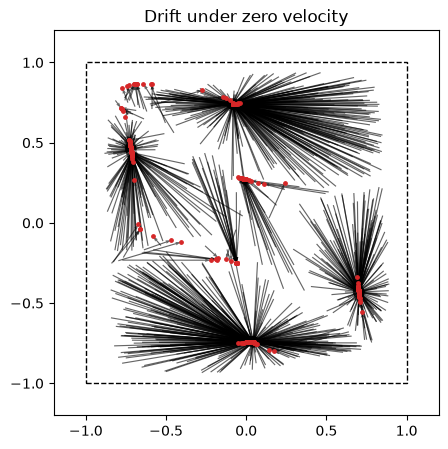

In [8]:
y0 = np.asarray(y_hold[:, 0]) * pos_sd + pos_mu      # decoded start
yT = np.asarray(y_hold[:, -1]) * pos_sd + pos_mu     # decoded after 300 stationary steps

plt.figure(figsize=(5, 5))
plt.quiver(y0[:, 0], y0[:, 1], yT[:, 0]-y0[:, 0], yT[:, 1]-y0[:, 1],
           angles="xy", scale_units="xy", scale=1, width=0.003, alpha=0.6)
plt.scatter(yT[:, 0], yT[:, 1], s=6, c="C3")
plt.gca().add_patch(plt.Rectangle((-1, -1), 2, 2, fill=False, ls="--"))
plt.xlim(-1.2, 1.2); plt.ylim(-1.2, 1.2); plt.gca().set_aspect("equal")
plt.title("Drift under zero velocity"); plt.show()